## Paso 1 — Cargamos el dataset ya tipado

Mismo parquet que los notebooks anteriores. Este notebook cubre las
Fases 7 y 8 del plan (§8-9): análisis temporal y geográfico.


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

INTERIM_DIR = Path("../datos/interim")
df = pd.read_parquet(INTERIM_DIR / "viajes_btura_tipado.parquet")

print(df.shape)


(41237, 17)


## Paso 2 — Serie diaria de viajes

Contamos viajes por día calendario, forzando a que aparezcan también los
días sin ningún registro (con 0), para no perderlos de vista. La media
móvil de 7 días suaviza el ruido y deja ver la tendencia.


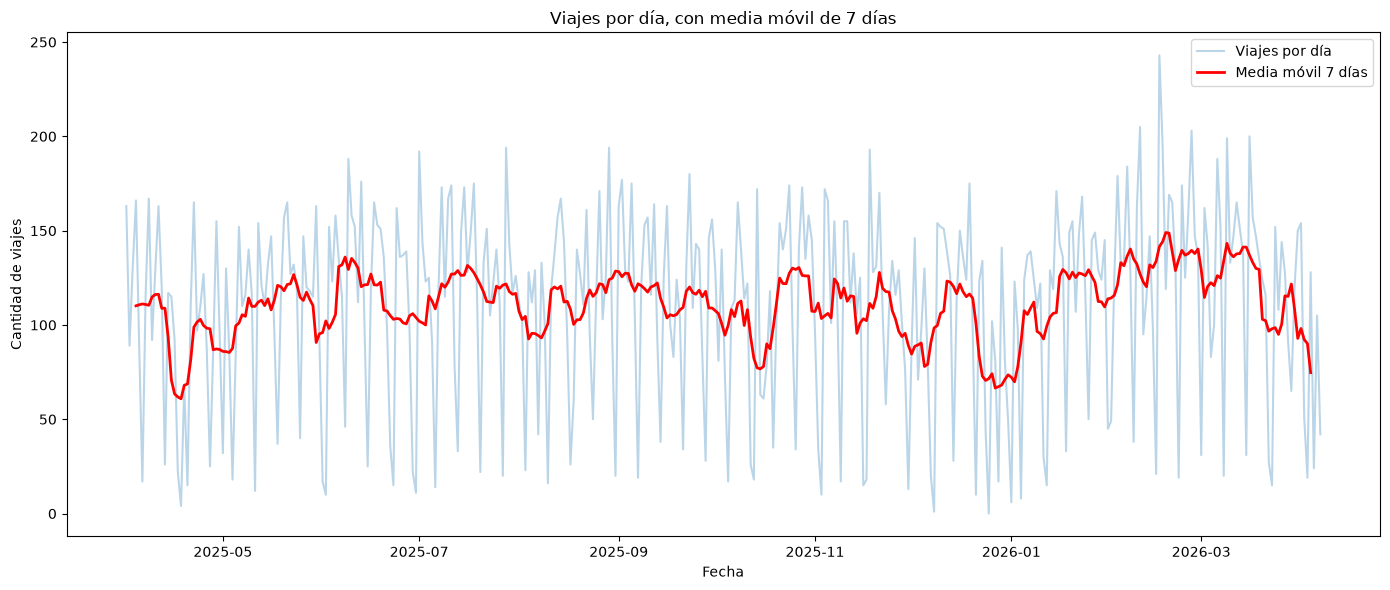

Total de días en la ventana: 372
Días con 0 viajes: 1
fechaCreacionFo
2025-12-25    0
Freq: D, dtype: int64


In [12]:
serie_diaria = df.groupby(df["fechaCreacionFo"].dt.date).size()
serie_diaria.index = pd.to_datetime(serie_diaria.index)
serie_diaria = serie_diaria.asfreq("D", fill_value=0)

media_movil_7d = serie_diaria.rolling(window=7, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(serie_diaria.index, serie_diaria.values, alpha=0.3, label="Viajes por día")
ax.plot(media_movil_7d.index, media_movil_7d.values, color="red", linewidth=2, label="Media móvil 7 días")
ax.set_xlabel("Fecha")
ax.set_ylabel("Cantidad de viajes")
ax.set_title("Viajes por día, con media móvil de 7 días")
ax.legend()
plt.tight_layout()
plt.savefig("../reportes/figures/05_serie_diaria_viajes.png", dpi=100)
plt.show()

print(f"Total de días en la ventana: {serie_diaria.shape[0]}")
print(f"Días con 0 viajes: {(serie_diaria == 0).sum()}")
print(serie_diaria[serie_diaria == 0])


## Paso 3 — Flete mediano por mes

Buscamos ajustes tarifarios visibles en el tiempo (§8 del plan, adaptado
a solo flete — tarifa no es confiable en este set, ver notebook `04`).
Se excluyen los fletes en 0/negativos ya conocidos.


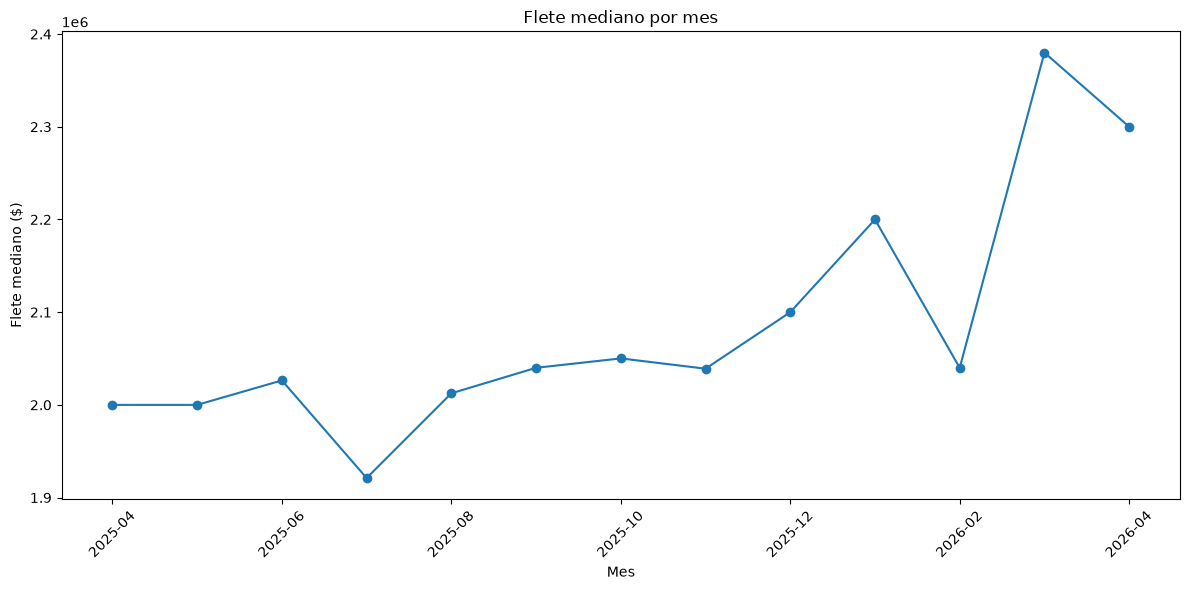

         flete_mediano  cambio_%
mes                             
2025-04      2000000.0       NaN
2025-05      2000000.0       0.0
2025-06      2026400.0       1.3
2025-07      1921110.0      -5.2
2025-08      2012490.0       4.8
2025-09      2040000.0       1.4
2025-10      2050125.0       0.5
2025-11      2039040.0      -0.5
2025-12      2100000.0       3.0
2026-01      2200000.0       4.8
2026-02      2039925.0      -7.3
2026-03      2380000.0      16.7
2026-04      2300000.0      -3.4


In [13]:
df["mes"] = df["fechaCreacionFo"].dt.to_period("M").astype(str)
flete_valido = df[df["fleteProduccionFo"] > 0]
flete_por_mes = flete_valido.groupby("mes")["fleteProduccionFo"].median()
cambio_pct = flete_por_mes.pct_change() * 100

fig, ax = plt.subplots(figsize=(12, 6))
flete_por_mes.plot(ax=ax, marker="o")
ax.set_xlabel("Mes")
ax.set_ylabel("Flete mediano ($)")
ax.set_title("Flete mediano por mes")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("../reportes/figures/05_flete_mediano_por_mes.png", dpi=100)
plt.show()

print(pd.DataFrame({"flete_mediano": flete_por_mes.round(0), "cambio_%": cambio_pct.round(1)}))


In [14]:
df["periodo"] = df["fechaCreacionFo"].apply(
    lambda f: "desde_marzo_2026" if f >= pd.Timestamp("2026-03-01") else "antes"
)
flete_valido = df[df["fleteProduccionFo"] > 0]

print("Cambio de flete mediano por tipo de vehículo (antes vs desde marzo 2026):")
comparacion_vehiculo = flete_valido.groupby(["idMedioTransporteFo", "periodo"])["fleteProduccionFo"].median().unstack()
comparacion_vehiculo["cambio_%"] = ((comparacion_vehiculo["desde_marzo_2026"] / comparacion_vehiculo["antes"]) - 1) * 100
print(comparacion_vehiculo.sort_values("cambio_%", ascending=False).round(1))

print("\nCambio de flete mediano por propiedad:")
comparacion_propiedad = flete_valido.groupby(["propiedad", "periodo"])["fleteProduccionFo"].median().unstack()
comparacion_propiedad["cambio_%"] = ((comparacion_propiedad["desde_marzo_2026"] / comparacion_propiedad["antes"]) - 1) * 100
print(comparacion_propiedad.round(1))


Cambio de flete mediano por tipo de vehículo (antes vs desde marzo 2026):
periodo                   antes  desde_marzo_2026  cambio_%
idMedioTransporteFo                                        
FP-2S3                1600000.0         2100000.0      31.2
FP-2S2                3303891.0         4200000.0      27.1
TC-3S2                1926965.0         2311200.0      19.9
TC-3S3                2002650.0         2400000.0      19.8
TC_TURBO              1650000.0         1900000.0      15.2
TC-4-MANOS            1950000.0         2200000.0      12.8
TC-2S3                2100000.0         2350000.0      11.9
TC_CAMNETA            1500000.0         1600000.0       6.7
TC_SENCI              2200000.0         2300000.0       4.5
FP-3S3                4647000.0         4746000.0       2.1
TC-2S2                2600000.0         2550000.0      -1.9
TC-DOBTROQ            3850000.0         1900000.0     -50.6
1                     2300000.0               NaN       NaN
FP-3S2                3300

## Síntesis del Paso 3 — Flete mediano por mes

El flete mediano se mantuvo estable (~$2,0M) de abril a noviembre 2025,
y subió ~17% entre noviembre 2025 y marzo 2026, con un salto de +16,7%
concentrado en marzo — el cambio mensual más grande de toda la ventana.

**Investigado y con hipótesis fuerte (no confirmada documentalmente con
la empresa):** el salario mínimo en Colombia subió 23% desde enero de
2026 (decretos de dic-2025, con disputa legal resuelta el 19-feb-2026).
Ese aumento se traslada al cálculo del SICE-TAC (que ya sabíamos que
actúa como piso del flete, hallazgo de HU-10.3), y MinTransporte
actualizó el SICE-TAC de forma progresiva desde enero de 2026
incorporando justamente salario mínimo, combustible y peajes
(formalizado en mayo 2026). Esa actualización progresiva explica que el
ajuste se acumule y se note fuerte recién en marzo.

**Confirmado como parejo, no puntual:** el aumento aparece en casi todos
los tipos de vehículo (+2% a +31%) y por igual en Propio (+13%) y
Tercero (+15%) — consistente con una causa de mercado/regulatoria, no
una negociación aislada. Dos excepciones: `TC-DOBTROQ` (-50,6%, ruido de
muestra chica, solo 67 viajes en todo el dataset) y `TC-2S2` (-1,9%,
plano pese a tener volumen real — posible indicio de que sus rutas
largas se negocian distinto al SICE-TAC, sin investigar más por ahora).

**Para el futuro modelo:** si este patrón se repite cada año (ajuste de
SMMLV/SICE-TAC en enero, con rezago de 1-3 meses hasta verse en el
flete real), el modelo predictivo necesita un componente temporal/anual
explícito — no puede asumir que el precio es estable en el tiempo.


## Paso 4 — Concentración de orígenes y destinos

Top de ciudades por volumen, con % acumulado, para ver cuántas ciudades
concentran la mayoría del movimiento (§9 del plan).


In [15]:
top_origen = df["origen"].value_counts(normalize=True) * 100
top_origen_acum = top_origen.cumsum()
print("Top 15 orígenes (% y % acumulado):")
print(pd.DataFrame({"pct": top_origen.round(1), "pct_acum": top_origen_acum.round(1)}).head(15))

top_destino = df["destino"].value_counts(normalize=True) * 100
top_destino_acum = top_destino.cumsum()
print("\nTop 15 destinos (% y % acumulado):")
print(pd.DataFrame({"pct": top_destino.round(1), "pct_acum": top_destino_acum.round(1)}).head(15))


Top 15 orígenes (% y % acumulado):
                           pct  pct_acum
origen                                  
BUENAVENTURA              74.7      74.7
BOGOTA, DISTRITO CAPITAL   2.9      77.6
FUNZA                      2.3      80.0
YUMBO                      2.0      82.0
COTA                       1.3      83.4
MANIZALES                  1.3      84.6
CALI                       1.0      85.6
MOSQUERA                   1.0      86.6
RIONEGRO                   0.9      87.4
PALMIRA                    0.8      88.2
MEDELLIN                   0.8      89.0
BELLO                      0.7      89.8
CAJICA                     0.6      90.3
GUARNE                     0.5      90.9
GIRARDOTA                  0.5      91.4

Top 15 destinos (% y % acumulado):
                           pct  pct_acum
destino                                 
BUENAVENTURA              47.0      47.0
MADRID                     4.7      51.7
YUMBO                      4.7      56.4
BOGOTA, DISTRITO CAPITAL   

## Paso 5 — Matriz origen-destino (top 20x20)

Mapa de calor de los pares origen-destino más frecuentes, para ver
rutas específicas en vez de ciudades por separado (§9 del plan).


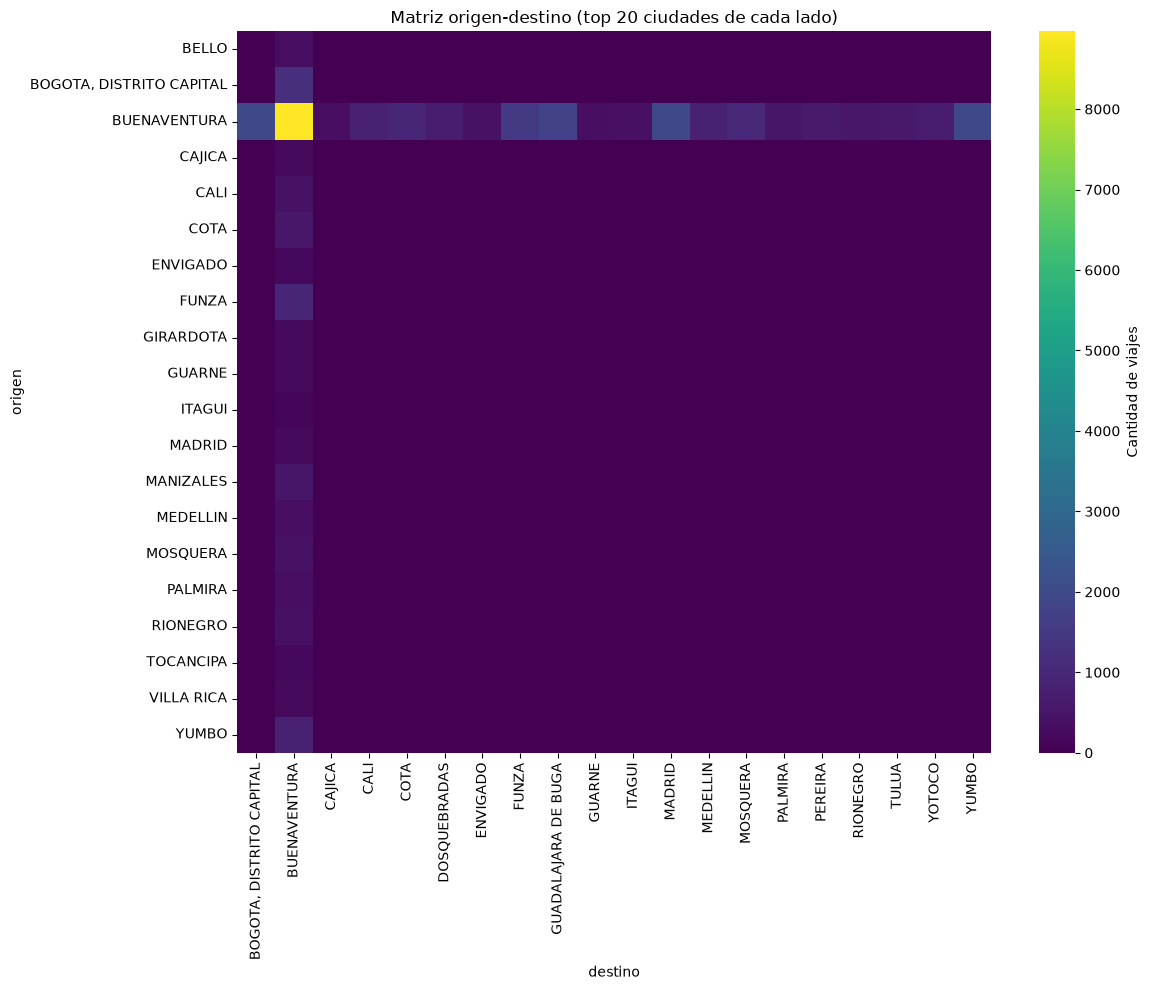

In [17]:
import seaborn as sns

top_origenes = df["origen"].value_counts().head(20).index
top_destinos = df["destino"].value_counts().head(20).index

matriz_od = pd.crosstab(df["origen"], df["destino"])
matriz_od_top = matriz_od.loc[matriz_od.index.isin(top_origenes), matriz_od.columns.isin(top_destinos)]

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(matriz_od_top, cmap="viridis", ax=ax, cbar_kws={"label": "Cantidad de viajes"})
ax.set_title("Matriz origen-destino (top 20 ciudades de cada lado)")
plt.tight_layout()
plt.savefig("../reportes/figures/05_matriz_origen_destino.png", dpi=100)
plt.show()



## Paso 6 — Flujo direccional por mes

Salidas desde Buenaventura vs entradas a Buenaventura, mes a mes (§9 del
plan). Se excluyen los viajes Buenaventura→Buenaventura (descontenerización,
ya tratada aparte desde el Paso 3 del notebook `04`).


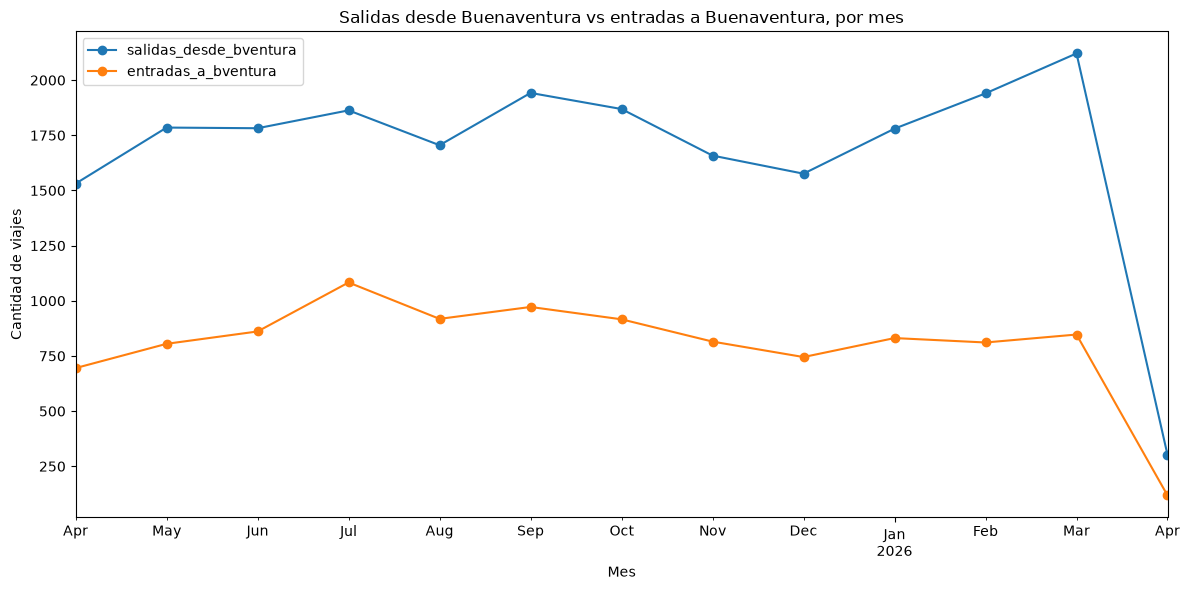

                 salidas_desde_bventura  entradas_a_bventura  \
fechaCreacionFo                                                
2025-04                            1531                  695   
2025-05                            1785                  805   
2025-06                            1782                  861   
2025-07                            1863                 1083   
2025-08                            1705                  918   
2025-09                            1942                  972   
2025-10                            1869                  916   
2025-11                            1658                  815   
2025-12                            1576                  745   
2026-01                            1780                  831   
2026-02                            1940                  811   
2026-03                            2121                  847   
2026-04                             302                  118   

                 ratio_salidas_entradas

In [18]:
salidas = df[(df["origen"] == "BUENAVENTURA") & (df["destino"] != "BUENAVENTURA")]
entradas = df[(df["destino"] == "BUENAVENTURA") & (df["origen"] != "BUENAVENTURA")]

salidas_mes = salidas.groupby(salidas["fechaCreacionFo"].dt.to_period("M")).size()
entradas_mes = entradas.groupby(entradas["fechaCreacionFo"].dt.to_period("M")).size()

flujo = pd.DataFrame({
    "salidas_desde_bventura": salidas_mes,
    "entradas_a_bventura": entradas_mes,
}).fillna(0)
flujo["ratio_salidas_entradas"] = (flujo["salidas_desde_bventura"] / flujo["entradas_a_bventura"]).round(2)

fig, ax = plt.subplots(figsize=(12, 6))
flujo[["salidas_desde_bventura", "entradas_a_bventura"]].plot(ax=ax, marker="o")
ax.set_xlabel("Mes")
ax.set_ylabel("Cantidad de viajes")
ax.set_title("Salidas desde Buenaventura vs entradas a Buenaventura, por mes")
plt.tight_layout()
plt.savefig("../reportes/figures/05_flujo_direccional.png", dpi=100)
plt.show()

print(flujo)


## Paso 7 — Consistencia de distancia por par origen-destino

¿La misma ruta siempre registra una distancia parecida, o varía mucho?
Mucha variación en el mismo par sugiere error de captura o ruta variable
(§9 del plan). Usamos coeficiente de variación (std/media) para comparar
rutas largas y cortas de forma justa. Solo pares con 20+ viajes, para no
sacar conclusiones de muestras chicas.


In [19]:
consistencia_od = df.groupby(["origen", "destino"]).agg(
    n=("distanciaTotal", "count"),
    distancia_media=("distanciaTotal", "mean"),
    distancia_std=("distanciaTotal", "std"),
).reset_index()

consistencia_od = consistencia_od[consistencia_od["n"] >= 20].copy()
consistencia_od["coef_variacion"] = (consistencia_od["distancia_std"] / consistencia_od["distancia_media"]).round(3)

print(f"Pares origen-destino con al menos 20 viajes: {consistencia_od.shape[0]}")
print("\nTop 15 pares con mayor variación relativa en distancia:")
print(consistencia_od.sort_values("coef_variacion", ascending=False).head(15)
      [["origen", "destino", "n", "distancia_media", "distancia_std", "coef_variacion"]].round(1))

print("\nPares más consistentes (menor variación):")
print(consistencia_od.sort_values("coef_variacion", ascending=True).head(5)
      [["origen", "destino", "n", "distancia_media", "distancia_std", "coef_variacion"]].round(1))


Pares origen-destino con al menos 20 viajes: 103

Top 15 pares con mayor variación relativa en distancia:
                       origen       destino     n  distancia_media  \
17               BUENAVENTURA  BUENAVENTURA  8966             10.2   
1                     ARMENIA  BUENAVENTURA    31            277.6   
26               BUENAVENTURA     CARTAGENA    57           1179.4   
21               BUENAVENTURA        CALDAS    72            533.1   
106              BUENAVENTURA       SOLEDAD    50           1171.1   
145              DOSQUEBRADAS  BUENAVENTURA   111            315.3   
178                 MANIZALES  BUENAVENTURA   518            312.0   
33               BUENAVENTURA    COPACABANA   186            466.1   
151                     FUNZA  BUENAVENTURA   968            519.2   
16               BUENAVENTURA   BUCARAMANGA    60            817.5   
74               BUENAVENTURA      MOSQUERA  1048            489.5   
6    BOGOTA, DISTRITO CAPITAL  BUENAVENTURA  1199     

## Síntesis del notebook 05 — Análisis temporal y geográfico

**Objetivo cumplido (Fases 7 y 8, §8-9 del plan):** entender cómo se
comporta el negocio en el tiempo y en el espacio.

**Temporal (Pasos 2-3):**
- Solo un día sin ningún registro en 372 días: 25 de diciembre de 2025 —
  confirma que `fechaCreacionFo` sigue de cerca la operación real.
- Sin quiebres estructurales de nivel; valles periódicos cada 1-2 meses
  sin explicar, quedan anotados como pendiente.
- Flete mediano estable (~$2,0M) de abril a noviembre 2025, sube ~17%
  hacia marzo 2026 (+16,7% ese mes). Investigado y con hipótesis fuerte:
  coincide con el aumento del 23% del salario mínimo colombiano
  (vigente desde enero 2026), trasladado al SICE-TAC (actualizado
  progresivamente desde enero 2026, formalizado en mayo). Confirmado
  como parejo en casi todos los vehículos y en Propio/Tercero por
  igual — consistente con causa macro/regulatoria. El futuro modelo
  necesita un componente temporal/anual.

**Geográfico (Pasos 4-7):**
- Buenaventura domina como origen (74,7%) mucho más que como destino
  (47,0%) — explicado por la composición de negocio ya conocida (`OPIM`
  67% puerto→interior vs `OPEX` ~9,5% interior→puerto).
- La matriz origen-destino confirma: casi todo el movimiento real es
  Buenaventura→interior; casi nada entre ciudades del interior entre sí.
- El flujo direccional nunca se invierte, pero la proporción
  salidas/entradas varía por mes (1,72 a 2,56), con tendencia a
  acentuarse desde noviembre 2025 — anotado, no investigado a fondo.
- **Hallazgo que resuelve una pregunta abierta del plan (§1.2):**
  `Distancia Total` es un valor planificado/de tabla por ruta, no
  medido en campo — varios pares registran exactamente la misma
  distancia en cientos de viajes distintos. Candidatos a revisión con
  variación real: `Buenaventura↔Cartagena/Caldas/Soledad`.

**Pendientes anotados, no investigados a fondo:**
- Valles periódicos en la serie diaria de viajes.
- Tendencia creciente en la proporción salidas/entradas desde
  noviembre 2025.
- `TC-2S2` sin subir de precio en el ajuste de marzo 2026 (notebook `04`).

**Qué le queda listo a los pasos siguientes:**
- Fase 9 (`06_outliers_y_sesgos.ipynb`): revisar los pares de distancia
  con variación real detectados aquí, junto con las categorías de
  muestra chica ya anotadas en el `04`.
- Futuro modelo predictivo: incluir un componente temporal/anual (por
  el ajuste SICE-TAC/salario mínimo), y tratar `distanciaTotal` como un
  valor casi categórico por ruta, no como una medición continua
  independiente.
